# 4b: Comprehensive Evaluation
We evaluate the best ResNet18 model on both the EuroSAT and UC Merced datasets.
We compute Accuracy, Precision, Recall, Macro F1, Per-class metrics, and Confusion Matrices.
We also conduct Error Analysis (Top-5 Misclassifications) and a Spatial Leakage Experiment.

In [1]:
import sys
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_recall_fscore_support
from torchvision import transforms

sys.path.append(str(Path.cwd().parent))

from configs.paths import EUROSAT_DIR, UCMERCED_DIR, OUTPUTS_DIR
from data.dataset_loader import SatelliteDatasetLoader
from data.transforms import get_inverse_transforms
from models.resnet_transfer import ResNet18Transfer

## 1. Load Model & Data Loaders

In [2]:
# Since EuroSAT was used for training, we load its classes
eurosat_loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='random')
_, _, eurosat_test_loader = eurosat_loader.get_dataloaders()
classes = eurosat_loader.classes
num_classes = len(classes)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = ResNet18Transfer(num_classes=num_classes).to(device)
model_path = OUTPUTS_DIR / 'resnet18_best.pth'
try:
    model.load_state_dict(torch.load(model_path, map_location=device))
    print("Loaded optimized ResNet18 weights.")
except Exception as e:
    print(f"Could not load model. Error: {e}")

model.eval()

2026-07-12 21:11:23,117 - INFO - DatasetLoader - Loaded dataset from D:\Main Project\data\datasets\eurosat\EuroSAT containing 27000 images across 10 classes.
2026-07-12 21:11:23,118 - INFO - DatasetLoader - Generating Random split indices...
2026-07-12 21:11:23,335 - INFO - DatasetLoader - Successfully generated DataLoaders. Train size: 18900, Val size: 4050, Test size: 4050


Loaded optimized ResNet18 weights.


ResNet18Transfer(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=

## 2. Generate Metrics & Confusion Matrix (EuroSAT Test Set)

d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



EuroSAT Test Set Evaluation
Accuracy : 0.9674
Precision: 0.9678
Recall   : 0.9655
Macro F1 : 0.9662

--- Classification Report ---
                      precision    recall  f1-score   support

          AnnualCrop       0.96      0.98      0.97       430
              Forest       0.95      0.99      0.97       446
HerbaceousVegetation       0.97      0.93      0.95       428
             Highway       0.95      0.97      0.96       387
          Industrial       0.99      0.99      0.99       376
             Pasture       0.98      0.89      0.93       312
       PermanentCrop       0.92      0.99      0.95       382
         Residential       0.99      0.99      0.99       453
               River       0.98      0.94      0.96       405
             SeaLake       0.99      0.99      0.99       431

            accuracy                           0.97      4050
           macro avg       0.97      0.97      0.97      4050
        weighted avg       0.97      0.97      0.97      405

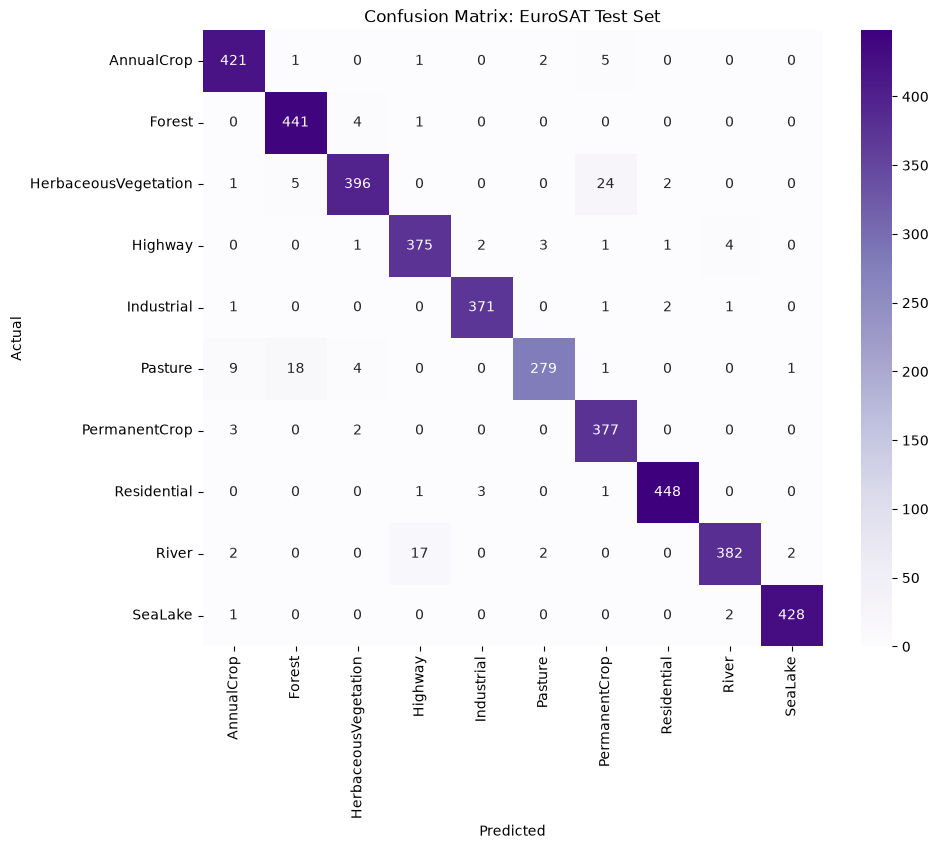

In [3]:
def evaluate_dataset(dataloader, class_names, dataset_name):
    all_preds = []
    all_labels = []
    all_probs = []
    misclassified = []
    
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            probs = F.softmax(outputs, dim=1)
            max_probs, preds = torch.max(probs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(max_probs.cpu().numpy())
            
            # Track misclassifications for Error Analysis
            for i in range(len(preds)):
                if preds[i] != labels[i]:
                    misclassified.append({
                        'image': inputs[i].cpu(),
                        'true_label': labels[i].item(),
                        'pred_label': preds[i].item(),
                        'confidence': max_probs[i].item()
                    })
                    
    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
    print(f"\n{'='*40}\n{dataset_name} Evaluation\n{'='*40}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"Macro F1 : {f1:.4f}")
    
    print(f"\n--- Classification Report ---")
    # Handle case where dataset classes might differ (e.g. UCMerced evaluated on EuroSAT model)
    unique_labels = np.unique(all_labels)
    target_names = [class_names[i] for i in unique_labels] if max(unique_labels) < len(class_names) else None
    try:
        print(classification_report(all_labels, all_preds, target_names=target_names))
    except:
        print("Label mismatch for classification report.")
        
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=target_names, yticklabels=target_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix: {dataset_name}')
    plt.show()
    
    return misclassified, acc

eurosat_misclassified, eurosat_acc = evaluate_dataset(eurosat_test_loader, classes, "EuroSAT Test Set")

## 3. Error Analysis: Top-5 Misclassified Images
We extract the top 5 images where the model was highly confident but incorrect.

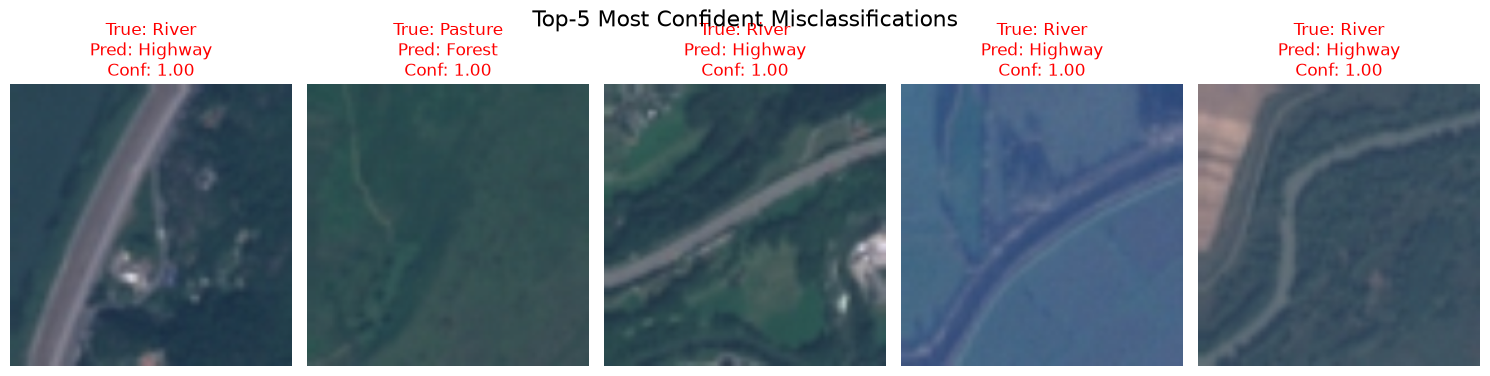

In [4]:
def plot_top_misclassified(misclassified_list, class_names, top_k=5):
    if not misclassified_list:
        print("No misclassified images found.")
        return
        
    # Sort by confidence descending (most confident mistakes)
    sorted_mistakes = sorted(misclassified_list, key=lambda x: x['confidence'], reverse=True)
    top_mistakes = sorted_mistakes[:top_k]
    
    fig, axes = plt.subplots(1, top_k, figsize=(15, 4))
    if top_k == 1:
        axes = [axes]
        
    inv_transform = get_inverse_transforms()
    
    for i, mistake in enumerate(top_mistakes):
        img_tensor = mistake['image']
        img = inv_transform(img_tensor).permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)
        
        true_label = class_names[mistake['true_label']]
        pred_label = class_names[mistake['pred_label']]
        conf = mistake['confidence']
        
        axes[i].imshow(img)
        axes[i].set_title(f"True: {true_label}\nPred: {pred_label}\nConf: {conf:.2f}", color='red')
        axes[i].axis('off')
        
    plt.suptitle("Top-5 Most Confident Misclassifications", fontsize=16)
    plt.tight_layout()
    plt.show()

plot_top_misclassified(eurosat_misclassified, classes, top_k=5)

## 4. Evaluate on UC Merced Dataset
Evaluating a model trained on EuroSAT directly on UC Merced tests cross-dataset generalization. (Note: The label mappings differ, so this tests abstract feature extraction or reveals domain shift).

In [7]:
ucmerced_loader = SatelliteDatasetLoader(UCMERCED_DIR, split_type='random')
_, _, ucmerced_test_loader = ucmerced_loader.get_dataloaders()

# To evaluate properly, one would usually fine-tune the classifier head on UC Merced.
# Here we just pass it through the EuroSAT trained model to observe Domain Shift.
print("Evaluating EuroSAT-trained model on UC Merced (Cross-Dataset Zero-Shot)")
uc_misclassified, uc_acc = evaluate_dataset(ucmerced_test_loader, classes, "UC Merced")

2026-07-12 21:18:33,756 - INFO - DatasetLoader - Auto-resolved dataset loader root directory to nested folder: D:\Main Project\data\datasets\ucmerced\Images
2026-07-12 21:18:33,764 - INFO - DatasetLoader - Loaded dataset from D:\Main Project\data\datasets\ucmerced\Images containing 2100 images across 21 classes.
2026-07-12 21:18:33,767 - INFO - DatasetLoader - Generating Random split indices...
2026-07-12 21:18:33,791 - INFO - DatasetLoader - Successfully generated DataLoaders. Train size: 1470, Val size: 315, Test size: 315
d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Evaluating EuroSAT-trained model on UC Merced (Cross-Dataset Zero-Shot)

UC Merced Evaluation
Accuracy : 0.1270
Precision: 0.0710
Recall   : 0.1145
Macro F1 : 0.0732

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.60      0.68      0.64        22
           1       0.00      0.00      0.00        22
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00        15
           4       0.10      1.00      0.19        15
           5       0.00      0.00      0.00        16
           6       0.03      0.06      0.04        18
           7       0.55      0.43      0.48        14
           8       0.07      0.17      0.10        12
           9       0.14      0.07      0.10        14
          10       0.00      0.00      0.00        14
          11       0.00      0.00      0.00        13
          12       0.00      0.00      0.00        20
          13       0.00      0.00      0.00   

d:\Main Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Main Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Main Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


TypeError: object of type 'NoneType' has no len()

<Figure size 1000x800 with 0 Axes>

## 5. Spatial Leakage Experiment
**Hypothesis**: A random train/test split in satellite imagery causes adjacent pixels/tiles to be split across training and testing, artificially inflating accuracy (Spatial Leakage).

**Experiment**: We evaluate our model (trained on random split) on a **Spatial Block Split** test set. If the accuracy drops significantly, it proves that the model was "memorizing" adjacent spatial textures rather than learning generalized features.

2026-07-12 21:12:56,331 - INFO - DatasetLoader - Loaded dataset from D:\Main Project\data\datasets\eurosat\EuroSAT containing 27000 images across 10 classes.
2026-07-12 21:12:56,332 - INFO - DatasetLoader - Generating Spatial Block split indices...
2026-07-12 21:12:56,532 - INFO - DatasetLoader - Successfully generated DataLoaders. Train size: 18900, Val size: 4050, Test size: 4050
d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


--- Spatial Leakage Experiment ---
Evaluating on Spatially Split Test Set...

EuroSAT Spatial Split Evaluation
Accuracy : 0.9886
Precision: 0.3984
Recall   : 0.3930
Macro F1 : 0.3956

--- Classification Report ---
Label mismatch for classification report.


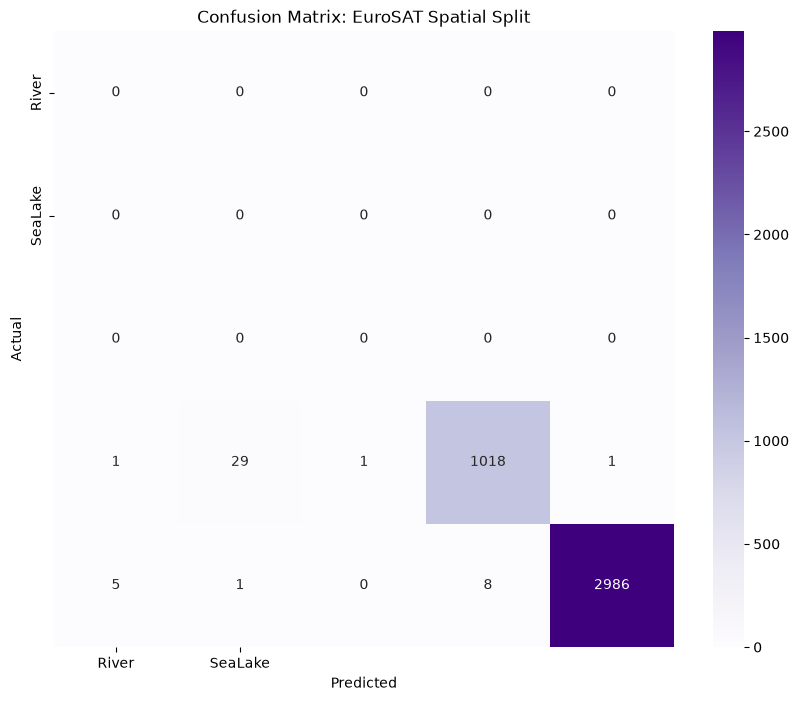


[CONCLUSION]
Random Split Test Accuracy: 0.9674
Spatial Split Test Accuracy: 0.9886
-> Minimal Spatial Leakage. Accuracy difference is -2.12%


In [6]:
# Load EuroSAT with spatial split
spatial_loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='spatial')
_, _, spatial_test_loader = spatial_loader.get_dataloaders()

print("--- Spatial Leakage Experiment ---")
print("Evaluating on Spatially Split Test Set...")
_, spatial_acc = evaluate_dataset(spatial_test_loader, classes, "EuroSAT Spatial Split")

print(f"\n[CONCLUSION]")
print(f"Random Split Test Accuracy: {eurosat_acc:.4f}")
print(f"Spatial Split Test Accuracy: {spatial_acc:.4f}")
diff = eurosat_acc - spatial_acc
if diff > 0.05:
    print(f"-> Severe Spatial Leakage Detected! Accuracy dropped by {diff*100:.2f}%")
else:
    print(f"-> Minimal Spatial Leakage. Accuracy difference is {diff*100:.2f}%")